# 03 · Análise exploratória

**Autor:** Adrian Cesar Gonçalves · **Fase CRISP-DM:** entendimento dos dados

Perguntas que esta etapa responde:

1. Quão desbalanceado é o alvo `falha` e o que isso implica para a métrica?
2. Como cada variável se distribui com e sem falha (Mann-Whitney U, rank-bisserial, Bonferroni)?
3. O tipo de produto está associado à falha, e com que força (qui-quadrado, V de Cramér)?
4. Como as variáveis se correlacionam (Spearman), inclusive por construção?
5. As regras físicas de falha (HDF, PWF, OSF) aparecem nos dados nas fronteiras documentadas?

In [1]:
# Ambiente: coloca src/ no sys.path (o notebook roda a partir de notebooks/ ou da raiz)
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from manutencao import eda
from manutencao.config import COLS_ENGENHARIA, COLS_MODOS, COLS_NUMERICAS_BRUTAS
from manutencao.preparacao import carregar_preparado
from manutencao.util import configurar_graficos, salvar_figura, salvar_tabela

configurar_graficos()
df = carregar_preparado()
NUMERICAS = COLS_NUMERICAS_BRUTAS + COLS_ENGENHARIA
df.shape

(10000, 17)

**Nota metodológica.** A EDA usa o conjunto completo (10.000 ciclos) porque é descritiva.
Nenhuma escolha de modelo sai daqui olhando o teste: os atributos físicos foram definidos
*a priori* pela documentação do dataset (notebook 01) e os hiperparâmetros são escolhidos por
validação cruzada só no treino (notebook 04).

In [3]:
resumo = eda.resumo_numerico(df, NUMERICAS)
salvar_tabela(resumo, "03_resumo_numerico", index=True)
resumo

,count,mean,std,min,25%,50%,75%,max,assimetria
temp_ar_k,10000.0,300.005,2.000,295.300,298.300,300.100,301.500,304.500,0.114
temp_processo_k,10000.0,310.006,1.484,305.700,308.800,310.100,311.100,313.800,0.015
rotacao_rpm,10000.0,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000,1.993
torque_nm,10000.0,39.987,9.969,3.800,33.200,40.100,46.800,76.600,-0.010
desgaste_ferramenta_min,10000.0,107.951,63.654,0.000,53.000,108.000,162.000,253.000,0.027
dif_temperatura_k,10000.0,10.001,1.001,7.600,9.300,9.800,11.000,12.100,-0.072
potencia_w,10000.0,6279.745,1067.418,1148.441,5561.184,6271.027,7003.003,10469.923,0.008
esforco_ferramenta_min_nm,10000.0,4314.665,2826.568,0.000,1963.650,4012.950,6279.000,16497.000,0.470


## 1. Balanceamento do alvo

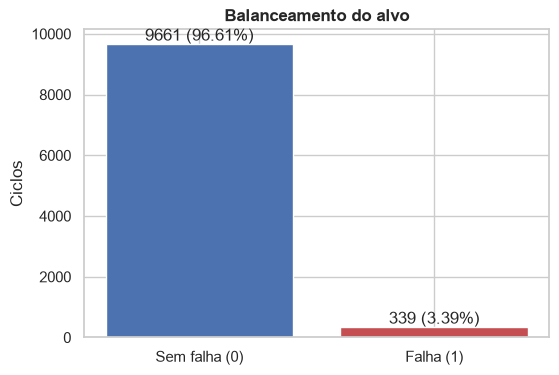

In [4]:
fig = eda.grafico_balanceamento(df)
salvar_figura(fig, "03_balanceamento");

,ciclos,% das falhas
falha_twf,46,13.57
falha_hdf,115,33.92
falha_pwf,95,28.02
falha_osf,98,28.91
falha_rnf,19,5.60


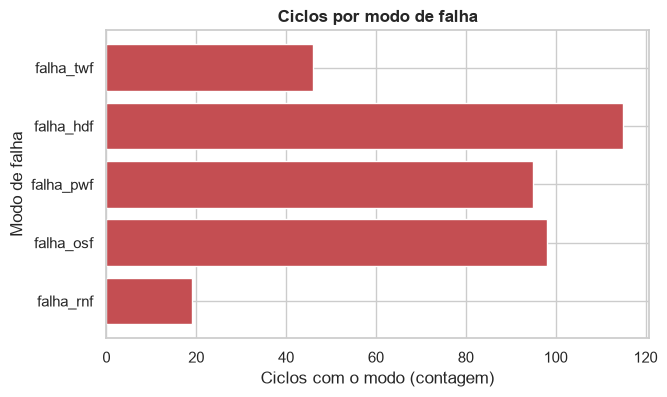

In [5]:
modos = df[COLS_MODOS].sum().rename("ciclos").to_frame()
modos["% das falhas"] = (100 * modos["ciclos"] / df["falha"].sum()).round(2)
salvar_tabela(modos, "03_modos_falha", index=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(modos.index, modos["ciclos"], color="#C44E52")
ax.invert_yaxis()
ax.set_title("Ciclos por modo de falha")
ax.set_xlabel("Ciclos com o modo (contagem)")
ax.set_ylabel("Modo de falha")
salvar_figura(fig, "03_modos_falha")
modos

In [6]:
n_falhas = int(df["falha"].sum())
soma_modos = int(modos["ciclos"].sum())
multiplos = int((df.loc[df["falha"] == 1, COLS_MODOS].sum(axis=1) > 1).sum())
sem_modo = int(((df["falha"] == 1) & (df[COLS_MODOS].sum(axis=1) == 0)).sum())
print(f"falhas: {n_falhas} · soma dos modos: {soma_modos}")
print(f"falhas com mais de um modo: {multiplos} · falhas sem modo: {sem_modo}")

falhas: 339 · soma dos modos: 373
falhas com mais de um modo: 24 · falhas sem modo: 9


Das **339 falhas**, a soma dos modos dá **373** porque **24** ciclos com falha têm mais de um modo
ao mesmo tempo, e **9** falhas não têm modo nenhum (as inconsistências documentadas no notebook 01).
HDF (115), OSF (98) e PWF (95) respondem pela maior parte; TWF (46) e RNF (19) são minoria.

Com 3,39 % de positivos (`03_balanceamento.png`), um modelo que sempre diz "sem falha" acerta
96,61 % dos ciclos: **acurácia não serve como métrica**. Por isso a modelagem usa PR-AUC.

## 2. Distribuições por classe

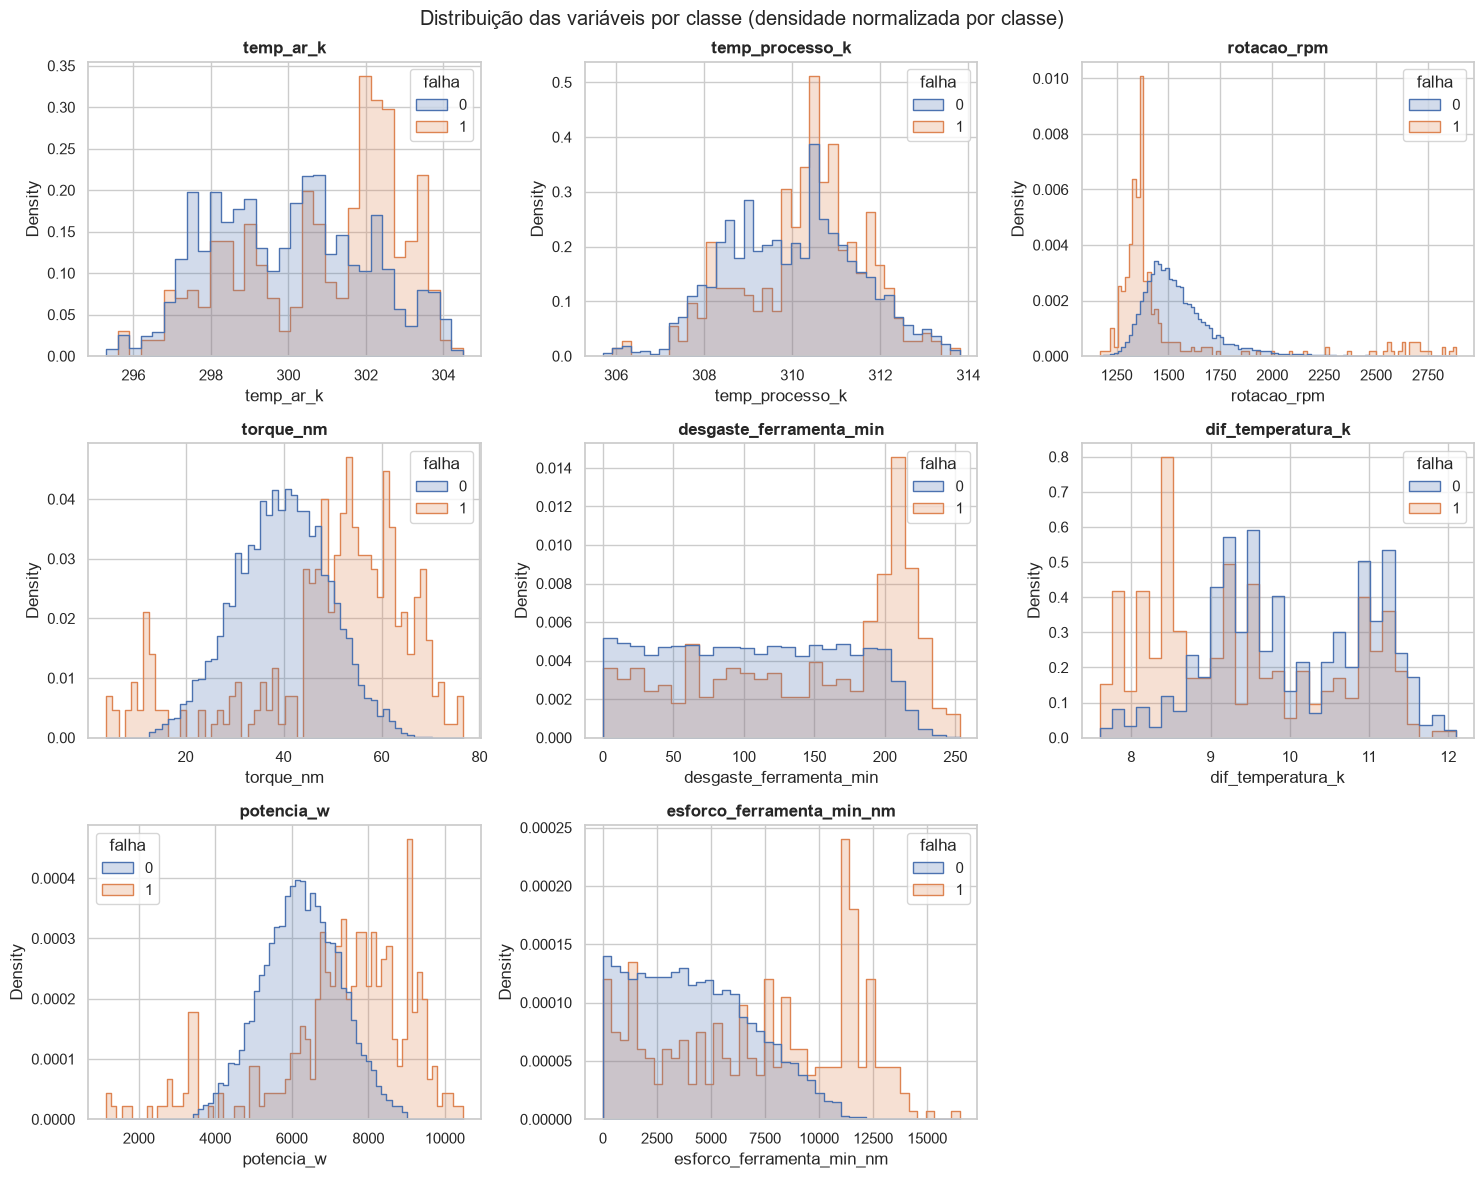

In [7]:
fig = eda.grafico_distribuicoes(df, NUMERICAS)
salvar_figura(fig, "03_distribuicoes");

In [8]:
mw = eda.mann_whitney(df, NUMERICAS)
salvar_tabela(mw, "03_mann_whitney")
mw

,variavel,mediana_falha,mediana_sem_falha,U,p_valor,p_bonferroni,rank_bisserial,significativo_5pct
0,torque_nm,53.700000,39.900000,2522586.0,2.262232e-64,1.809786e-63,0.540473,True
1,rotacao_rpm,1365.000000,1507.000000,764120.0,9.706908e-63,7.765526e-62,-0.533373,True
2,potencia_w,7611.429737,6243.046225,2442070.5,1.654911e-53,1.323929e-52,0.491305,True
3,esforco_ferramenta_min_nm,7681.800000,3952.800000,2307100.5,1.336245e-37,1.068996e-36,0.408882,True
4,dif_temperatura_k,9.300000,9.800000,1105789.0,2.403332e-24,1.922665e-23,-0.324725,True
5,desgaste_ferramenta_min,165.000000,107.000000,2168468.0,2.916461e-24,2.333169e-23,0.324223,True
6,temp_ar_k,301.600000,300.000000,2072260.0,8.656108e-17,6.924887e-16,0.265472,True
7,temp_processo_k,310.400000,310.000000,1846182.5,6.486083e-05,5.188867e-04,0.127412,True


Leitura da tabela `03_mann_whitney.csv`:

- As **8 variáveis** são significativas após Bonferroni (maior `p_bonferroni` = 5,2 × 10⁻⁴,
  em `temp_processo_k`). Com 10.000 ciclos, p pequeno é fácil: o que importa é o tamanho de efeito.
- Maiores |rank-bisserial|: **torque** (+0,54; mediana 53,7 Nm nas falhas × 39,9 Nm sem falha),
  **rotação** (−0,53; 1365 × 1507 rpm), **potência** (+0,49) e **esforço da ferramenta** (+0,41).
- Sinal negativo = valores menores nas falhas: rotação baixa e **diferença de temperatura**
  menor (−0,32; 9,3 × 9,8 K), coerente com a regra HDF.
- `temp_processo_k` tem o menor efeito (+0,13): sozinha quase não separa as classes.
- Mann-Whitney em vez de teste t: várias variáveis são assimétricas (rotação, assimetria 1,99 em
  `03_resumo_numerico.csv`) e as classes têm tamanhos muito diferentes (339 × 9.661).

## 3. Tipo de produto

,tipo,ciclos,falhas,taxa_falha_pct
0,L,6000,235,3.92
1,M,2997,83,2.77
2,H,1003,21,2.09


,variavel,qui2,gl,p_valor,v_cramer
0,tipo,13.751717,2,0.001032,0.037083


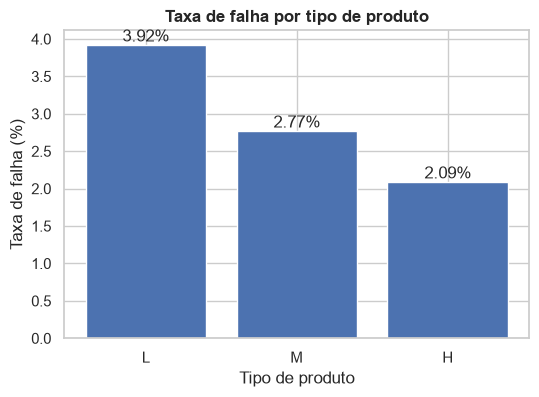

In [9]:
taxa = eda.taxa_por_categoria(df, "tipo")
salvar_tabela(taxa, "03_taxa_falha_por_tipo")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(taxa["tipo"].astype(str), taxa["taxa_falha_pct"], color="#4C72B0")
for i, v in enumerate(taxa["taxa_falha_pct"]):
    ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom")
ax.set_title("Taxa de falha por tipo de produto")
ax.set_xlabel("Tipo de produto")
ax.set_ylabel("Taxa de falha (%)")
salvar_figura(fig, "03_taxa_falha_por_tipo")
qq = eda.qui_quadrado(df, "tipo")
salvar_tabela(pd.DataFrame([qq]), "03_qui_quadrado_tipo")
display(taxa)
pd.DataFrame([qq])

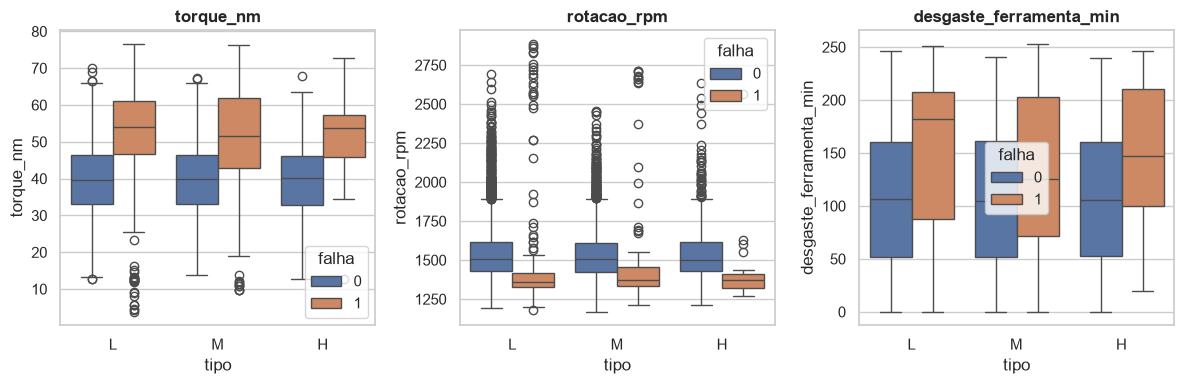

In [10]:
fig = eda.grafico_boxplot_por_tipo(df, ["torque_nm", "rotacao_rpm", "desgaste_ferramenta_min"])
salvar_figura(fig, "03_boxplot_por_tipo");

A taxa de falha cai de **L (3,92 %)** para **M (2,77 %)** e **H (2,09 %)**
(`03_taxa_falha_por_tipo.csv`). O qui-quadrado dá **χ² = 13,75** com 2 graus de liberdade e
**p = 0,001**: a associação é estatisticamente significativa, mas o **V de Cramér = 0,037** indica
efeito **muito pequeno**. O tipo importa sobretudo pelo limite de sobrecarga do OSF, que é
diferente para L, M e H (seção 5), e não por deslocar torque, rotação ou desgaste
(`03_boxplot_por_tipo.png`).

## 4. Correlações

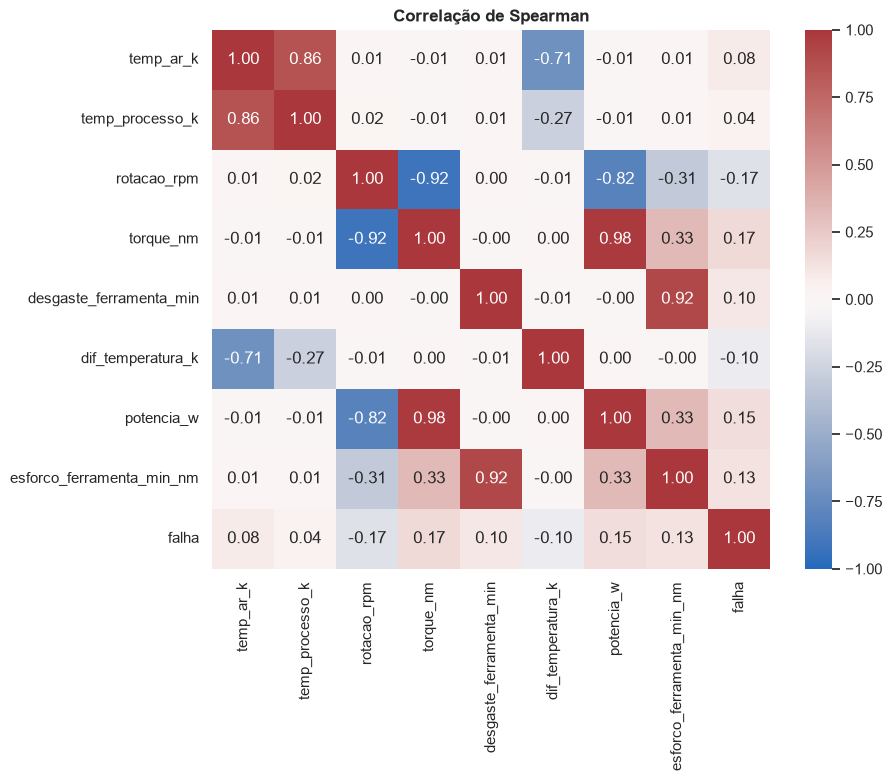

In [11]:
fig = eda.grafico_correlacao(df, NUMERICAS + ["falha"])
salvar_figura(fig, "03_correlacao_spearman");

In [12]:
corr = df[NUMERICAS + ["falha"]].corr(method="spearman")
pares = (
    corr.where(
        ~pd.DataFrame(
            [[i <= j for j in range(len(corr))] for i in range(len(corr))],
            index=corr.index,
            columns=corr.columns,
        )
    )
    .stack()
    .rename("rho")
    .reset_index()
)
pares.reindex(pares["rho"].abs().sort_values(ascending=False).index).head(8).round(3)

,level_0,level_1,rho
57,potencia_w,torque_nm,0.978
67,esforco_ferramenta_min_nm,desgaste_ferramenta_min,0.919
29,torque_nm,rotacao_rpm,-0.916
9,temp_processo_k,temp_ar_k,0.864
56,potencia_w,rotacao_rpm,-0.817
45,dif_temperatura_k,temp_ar_k,-0.706
66,esforco_ferramenta_min_nm,torque_nm,0.332
69,esforco_ferramenta_min_nm,potencia_w,0.326


Pares fortes **por construção** (Spearman, `03_correlacao_spearman.png`):

- `potencia_w` × `torque_nm`: ρ = 0,98 e `potencia_w` × `rotacao_rpm`: ρ = −0,82 (potência = torque × rotação).
- `esforco_ferramenta_min_nm` × `desgaste_ferramenta_min`: ρ = 0,92 (esforço = desgaste × torque).
- `torque_nm` × `rotacao_rpm`: ρ = −0,92 (o simulador gera o torque em função da rotação).
- `temp_processo_k` × `temp_ar_k`: ρ = 0,86 e `dif_temperatura_k` × `temp_ar_k`: ρ = −0,71.

Implicação: há **multicolinearidade** entre atributos brutos e derivados. Para a regressão
logística isso instabiliza os coeficientes (pedir regularização); para árvores e boosting é
irrelevante. Nenhuma variável isolada tem correlação forte com `falha` (|ρ| ≤ 0,17 no mapa):
a falha depende de **combinações** de variáveis, como mostram as regras abaixo.

## 5. Regras físicas de falha

Fronteiras documentadas do AI4I 2020 (MATZKA, 2020), reproduzidas no notebook 01:

- **HDF** (dissipação de calor): `dif_temperatura_k` < 8,6 K **e** `rotacao_rpm` < 1380 rpm.
- **PWF** (potência): `potencia_w` = torque × rotação × 2π/60 fora de [3500, 9000] W.
- **OSF** (sobrecarga): `desgaste_ferramenta_min` × `torque_nm` acima de 11.000 (L),
  12.000 (M) ou 13.000 (H) min·Nm.

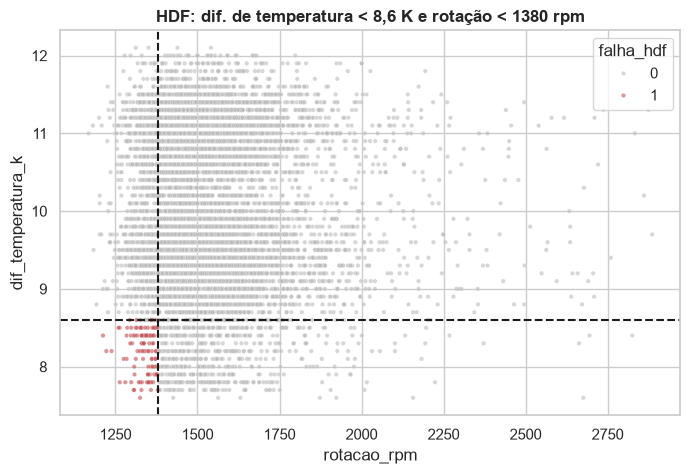

In [13]:
salvar_figura(eda.grafico_regra_hdf(df), "03_regra_hdf");

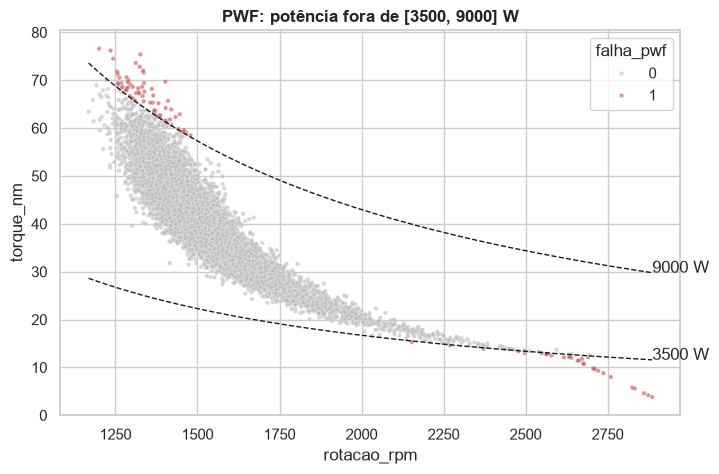

In [14]:
salvar_figura(eda.grafico_regra_pwf(df), "03_regra_pwf");

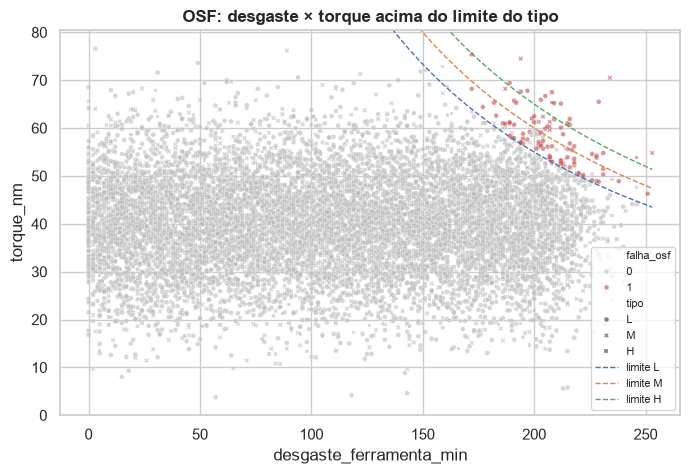

In [15]:
salvar_figura(eda.grafico_regra_osf(df), "03_regra_osf");

As falhas de cada modo ficam **exatamente além das fronteiras** documentadas:

- **HDF** (`03_regra_hdf.png`): todos os pontos vermelhos ficam no canto de diferença de
  temperatura < 8,6 K e rotação < 1380 rpm.
- **PWF** (`03_regra_pwf.png`): os pontos vermelhos ficam acima da curva de 9000 W ou abaixo da
  de 3500 W.
- **OSF** (`03_regra_osf.png`): os pontos vermelhos ficam acima da curva de limite do tipo.

O notebook 01 (`01_regras_vs_rotulos.csv`) confirma a mesma coisa em números: as regras batem
100 % com os rótulos HDF (115), PWF (95) e OSF (98). Por isso os atributos
`dif_temperatura_k`, `potencia_w` e `esforco_ferramenta_min_nm` separam esses três modos.
TWF (46) e RNF (19) não têm fronteira desenhada a partir de um único ciclo: o TWF depende de um
sorteio da vida útil da ferramenta e o RNF é aleatório (UCI MACHINE LEARNING REPOSITORY, 2020).
Esses modos não são previsíveis pelas leituras de um ciclo.

## Conclusões da etapa

- O alvo é **desbalanceado**: 339 falhas em 10.000 ciclos (**3,39 %**); acurácia de 96,61 % é
  trivial (`03_balanceamento.png`).
- HDF (115), OSF (98) e PWF (95) são os modos mais frequentes; 24 falhas têm mais de um modo e
  9 não têm modo (`03_modos_falha.csv`).
- Todas as 8 variáveis diferem entre as classes após Bonferroni; os maiores efeitos são de
  **torque (r = +0,54)**, **rotação (r = −0,53)** e **potência (r = +0,49)** (`03_mann_whitney.csv`).
- O tipo de produto tem associação significativa (χ² = 13,75; p = 0,001), mas fraca
  (**V de Cramér = 0,037**); taxa de falha L 3,92 %, M 2,77 %, H 2,09 %
  (`03_taxa_falha_por_tipo.csv`, `03_qui_quadrado_tipo.csv`).
- Há correlações fortes por construção (potência × torque ρ = 0,98; esforço × desgaste ρ = 0,92;
  torque × rotação ρ = −0,92).
- As fronteiras das regras HDF, PWF e OSF aparecem nos gráficos exatamente como documentadas.

**Implicações para a modelagem (notebook 04)**

- Métrica principal **PR-AUC** (e não acurácia), por causa dos 3,39 % de positivos.
- Usar os **atributos físicos** (`dif_temperatura_k`, `potencia_w`, `esforco_ferramenta_min_nm`),
  que separam HDF, PWF e OSF.
- Esperar dificuldade com **TWF e RNF**: não têm região própria em um único ciclo.
- Usar o **tipo como atributo ordinal** (L < M < H); o efeito direto é pequeno, mas ele define o
  limite de sobrecarga do OSF.